# Credit Risk Profiling & NPA Monitoring

End-to-end portfolio analysis using a synthetic retail-loan dataset. The notebook covers EDA, feature engineering, logistic-regression PD modelling, risk segmentation and model evaluation.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, roc_curve

df = pd.read_excel(r'C:\Users\2024\Downloads\Credit_Risk_NPA_Monitoring_Dashboard-main\credit_risk_analysis.xlsx', parse_dates=['application_date'])
df.head()


,loan_id,application_date,age,annual_income,employment_years,loan_amount,tenure_months,interest_rate_pct,credit_score,dti_pct,...,employment_type,region,existing_loans,monthly_obligations,days_past_due,default_flag,npa_flag,risk_score,risk_band,pd_estimate
0,LN103286,2023-01-01,35,69900,11.2,351000,48,12.54,605,16.4,...,Salaried,West,0,9336.51,10,0,0,29.25,Moderate,0.0763
1,LN100345,2023-01-01,40,145200,6.7,265000,72,11.62,731,15.2,...,Salaried,West,2,5128.58,0,0,0,20.69,Low,0.0105
2,LN104461,2023-01-02,55,63700,7.0,657000,48,12.90,791,40.3,...,Salaried,West,0,17593.07,5,0,0,20.33,Low,0.0138
3,LN104079,2023-01-02,35,29000,6.1,208000,36,8.96,812,56.0,...,Self-employed,North,2,6610.47,0,0,0,25.15,Moderate,0.0313
4,LN103074,2023-01-02,31,24000,11.2,632000,60,14.10,648,8.3,...,Self-employed,Central,2,14738.32,15,0,0,25.52,Moderate,0.0350


## 1. Portfolio EDA


In [3]:
print(df.shape)
print(df.isna().sum().sort_values(ascending=False).head())
print(df[['loan_amount','credit_score','dti_pct','ltv_pct','pd_estimate','risk_score']].describe().T)


(5000, 25)
loan_id       0
dependents    0
risk_band     0
risk_score    0
npa_flag      0
dtype: int64
               count           mean            std         min          25%  \
loan_amount   5000.0  551891.600000  390529.076563  37000.0000  286000.0000   
credit_score  5000.0     703.398600      61.495675    492.0000     660.0000   
dti_pct       5000.0      34.464200      13.834050      5.0000      24.7000   
ltv_pct       5000.0      88.524060      26.678772     55.6000      65.8000   
pd_estimate   5000.0       0.054968       0.056906      0.0017       0.0193   
risk_score    5000.0      26.403962       5.543687      8.5100      22.5300   

                      50%           75%           max  
loan_amount   449000.0000  696000.00000  4.706000e+06  
credit_score     704.0000     746.00000  8.500000e+02  
dti_pct           34.4000      44.00000  8.350000e+01  
ltv_pct           81.2000     106.70000  1.538000e+02  
pd_estimate        0.0359       0.06955  5.411000e-01  
risk_s

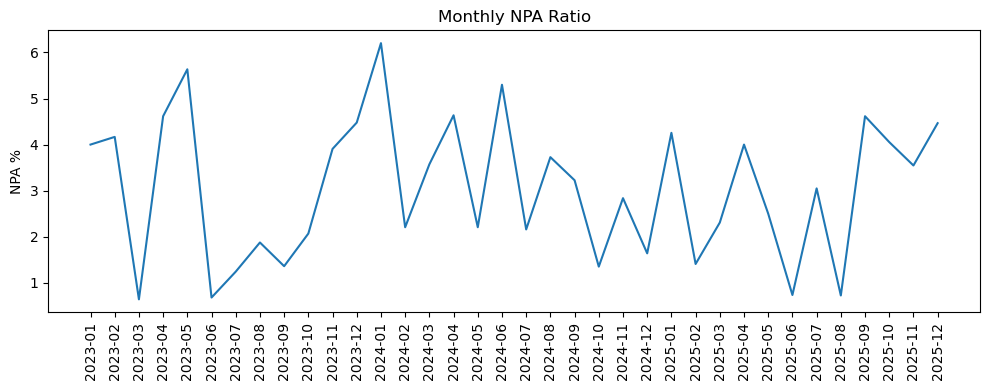

In [5]:
monthly = df.groupby(df['application_date'].dt.to_period('M')).agg(
    loans=('loan_id','count'), exposure=('loan_amount','sum'),
    npa_ratio=('npa_flag','mean'), avg_pd=('pd_estimate','mean')
).reset_index()
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(monthly['application_date'].astype(str), monthly['npa_ratio']*100)
ax.set_title('Monthly NPA Ratio'); ax.set_ylabel('NPA %'); ax.tick_params(axis='x', rotation=90)
plt.tight_layout()


## 2. Feature engineering and train/test split


In [7]:
target = 'default_flag'
features = ['age','annual_income','employment_years','loan_amount','tenure_months','interest_rate_pct',
            'credit_score','dti_pct','prior_delinquencies','ltv_pct','dependents','purpose',
            'employment_type','region','existing_loans','monthly_obligations']
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
pre = ColumnTransformer([('num', Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())]), num_cols),
                         ('cat', Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore'))]), cat_cols)])
model = Pipeline([('pre',pre),('clf',LogisticRegression(max_iter=1000, class_weight='balanced'))])
model.fit(X_train, y_train)


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['age', 'annual_income',
                                                   'employment_years',
                                                   'loan_amount',
                                                   'tenure_months',
                                                   'interest_rate_pct',
                                                   'credit_score', 'dti_pct',
                                                   'prior_delinquencies',
                                                   'ltv_pct', 'dependents',
                                                   'existing_loans',
                                                   'monthly_obligations']),
                                                 ('cat',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['purpose', 'employment_type',
                                                   'region'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

## 3. Model evaluation


In [9]:
proba = model.predict_proba(X_test)[:,1]
pred = (proba >= 0.20).astype(int)  # lower threshold to prioritize risk capture
print('ROC-AUC:', round(roc_auc_score(y_test, proba), 4))
print(classification_report(y_test, pred, digits=3))


ROC-AUC: 0.7716
              precision    recall  f1-score   support

           0      0.991     0.188     0.315      1178
           1      0.068     0.972     0.127        72

    accuracy                          0.233      1250
   macro avg      0.530     0.580     0.221      1250
weighted avg      0.938     0.233     0.305      1250



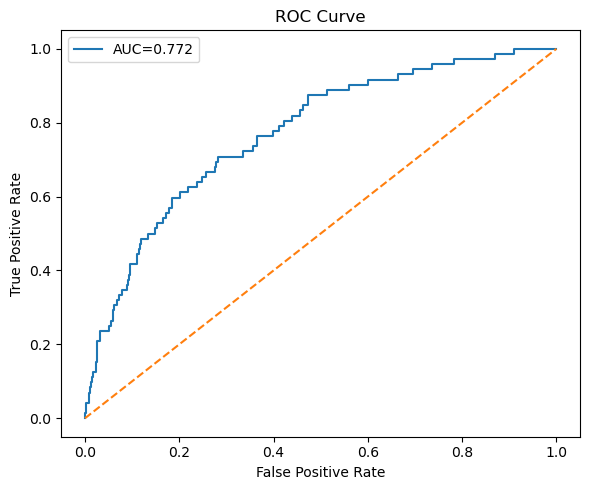

In [11]:
fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure(figsize=(6,5)); plt.plot(fpr,tpr,label=f'AUC={roc_auc_score(y_test,proba):.3f}')
plt.plot([0,1],[0,1],'--'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC Curve'); plt.legend(); plt.tight_layout()


## 4. Risk bands and monitoring logic

Operational bands: Low (<5% PD), Moderate (5–10%), High (10–20%), Very High (>20%). Early-warning status is triggered by 30–89 DPD, high DTI, high LTV, repeated delinquency or low bureau score. These thresholds are illustrative and should be recalibrated using a bank's historical outcomes and policy.


In [13]:
def band(p):
    if p < .05: return 'Low'
    if p < .10: return 'Moderate'
    if p < .20: return 'High'
    return 'Very High'
df['model_pd'] = model.predict_proba(df[features])[:,1]
df['model_risk_band'] = df['model_pd'].map(band)
df['early_warning'] = ((df.days_past_due.between(30,89)) | (df.dti_pct>=50) | (df.ltv_pct>=85) | (df.prior_delinquencies>=2) | (df.credit_score<650)).astype(int)
df[['loan_id','model_pd','model_risk_band','early_warning']].head()


,loan_id,model_pd,model_risk_band,early_warning
0,LN103286,0.606928,Very High,1
1,LN100345,0.107492,High,0
2,LN104461,0.147733,High,1
3,LN104079,0.245006,Very High,1
4,LN103074,0.366212,Very High,1


## 5. Export model scoring output


In [19]:
out = df[
    [
        'loan_id',
        'application_date',
        'loan_amount',
        'credit_score',
        'dti_pct',
        'ltv_pct',
        'days_past_due',
        'npa_flag'
    ]
]

import os
os.makedirs('../outputs', exist_ok=True)

out.to_csv('../outputs/model_scoring_output.csv', index=False)